# Imbalanced Datasets — Guided Examples
This notebook demonstrates class imbalance, baseline metrics, class weighting, oversampling, SMOTE, cross-validation, threshold selection, and final test evaluation.

**Leakage rule:** split first. Fit samplers only inside the training pipeline. Do not use the test set to choose parameters or thresholds.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score,
    average_precision_score, roc_auc_score, classification_report,
    ConfusionMatrixDisplay, precision_recall_curve
)
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler

RANDOM_STATE = 42

## 1. Generate a rare-positive classification dataset
This synthetic dataset has 2% positives. The example is for learning, not a substitute for validating on representative production data.

,count
Class 0,4882
Class 1,118


Positive prevalence: 2.36%


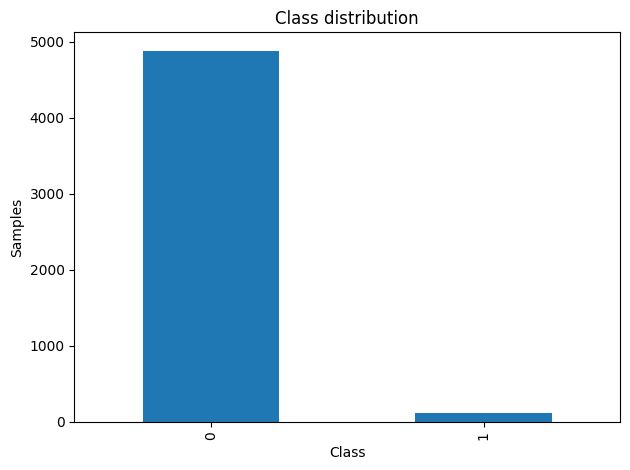

Train prevalence: 2.37%; test prevalence: 2.32%


In [2]:
X, y = make_classification(
    n_samples=5000, n_features=20, n_informative=6, n_redundant=3,
    weights=[0.98, 0.02], class_sep=1.0, random_state=RANDOM_STATE
)
counts = pd.Series(y).value_counts().sort_index()
display(counts.rename(index={0: "Class 0", 1: "Class 1"}).to_frame("count"))
print(f"Positive prevalence: {y.mean():.2%}")
counts.plot(kind="bar", title="Class distribution")
plt.xlabel("Class")
plt.ylabel("Samples")
plt.tight_layout()
plt.show()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE
)
print(f"Train prevalence: {y_train.mean():.2%}; test prevalence: {y_test.mean():.2%}")
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

## 2. Majority-class baseline
Accuracy alone can hide a model that never detects a positive case.

Accuracy: 0.9768
Balanced accuracy: 0.5
Precision: 0.0
Recall: 0.0
F1: 0.0
Average precision: 0.0232


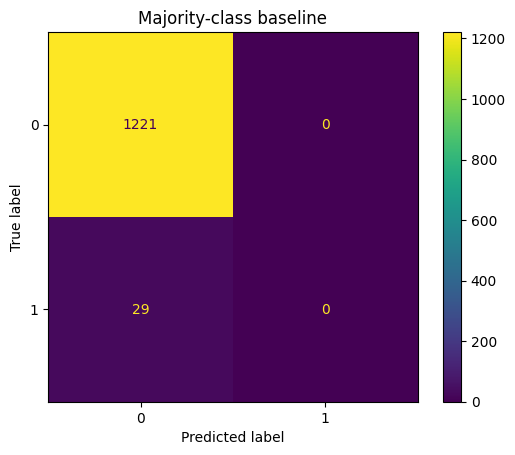

In [3]:
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train)
dummy_pred = dummy.predict(X_test)
dummy_prob = dummy.predict_proba(X_test)[:, 1]
print("Accuracy:", accuracy_score(y_test, dummy_pred))
print("Balanced accuracy:", balanced_accuracy_score(y_test, dummy_pred))
print("Precision:", precision_score(y_test, dummy_pred, zero_division=0))
print("Recall:", recall_score(y_test, dummy_pred, zero_division=0))
print("F1:", f1_score(y_test, dummy_pred, zero_division=0))
print("Average precision:", average_precision_score(y_test, dummy_prob))
ConfusionMatrixDisplay.from_predictions(y_test, dummy_pred)
plt.title("Majority-class baseline")
plt.show()

## 3. Compare imbalance strategies using the same folds
Sampling is inside an `imblearn` pipeline. Each fold fits the scaler and sampler on its training partition only.

In [4]:
strategies = {
    "Unweighted logistic": Pipeline([
        ("scale", StandardScaler()),
        ("model", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
    ]),
    "Class weighted": Pipeline([
        ("scale", StandardScaler()),
        ("model", LogisticRegression(class_weight="balanced", max_iter=2000,
                                     random_state=RANDOM_STATE))
    ]),
    "Random oversampling": Pipeline([
        ("scale", StandardScaler()),
        ("sampler", RandomOverSampler(random_state=RANDOM_STATE)),
        ("model", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
    ]),
    "SMOTE": Pipeline([
        ("scale", StandardScaler()),
        ("sampler", SMOTE(random_state=RANDOM_STATE)),
        ("model", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
    ]),
    "Random undersampling": Pipeline([
        ("scale", StandardScaler()),
        ("sampler", RandomUnderSampler(random_state=RANDOM_STATE)),
        ("model", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
    ]),
}
scoring = {
    "ap": "average_precision",
    "recall": "recall",
    "precision": "precision",
    "balanced_accuracy": "balanced_accuracy",
}
rows = []
for name, estimator in strategies.items():
    start = time.perf_counter()
    result = cross_validate(estimator, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    rows.append({
        "strategy": name,
        **{metric: result[f"test_{metric}"].mean() for metric in scoring},
        "fit_and_score_seconds": time.perf_counter() - start
    })
results = pd.DataFrame(rows).set_index("strategy").sort_values("ap", ascending=False)
display(results.round(3))

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 772, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/connection.py", line 38, in get_or_create_client
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 104, in __init__
ConnectionRefusedError: [Errno 111] Connection refused


Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

/opt/pyvenv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


,ap,recall,precision,balanced_accuracy,fit_and_score_seconds
strategy,,,,,
Unweighted logistic,0.178,0.035,0.400,0.517,10.329
Random oversampling,0.153,0.707,0.065,0.730,0.055
SMOTE,0.153,0.696,0.069,0.734,0.045
Class weighted,0.145,0.729,0.067,0.741,0.045
Random undersampling,0.101,0.651,0.051,0.676,0.024


## 4. Fit a selected pipeline and evaluate on the held-out test set
For the demonstration, use class weighting. In a project, select the strategy using CV evidence and operational constraints.

Accuracy: 0.756
Balanced accuracy: 0.6563
Precision: 0.0519
Recall: 0.5517
F1: 0.095
Average precision: 0.1245
ROC-AUC: 0.7519
              precision    recall  f1-score   support

           0       0.99      0.76      0.86      1221
           1       0.05      0.55      0.09        29

    accuracy                           0.76      1250
   macro avg       0.52      0.66      0.48      1250
weighted avg       0.96      0.76      0.84      1250



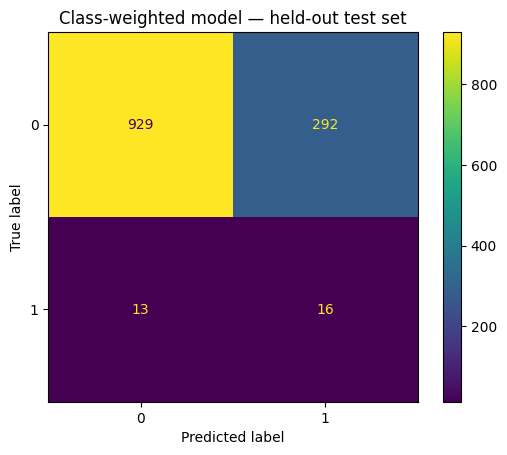

In [5]:
selected = strategies["Class weighted"]
selected.fit(X_train, y_train)
test_prob = selected.predict_proba(X_test)[:, 1]
test_pred = selected.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, test_pred), 4))
print("Balanced accuracy:", round(balanced_accuracy_score(y_test, test_pred), 4))
print("Precision:", round(precision_score(y_test, test_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, test_pred, zero_division=0), 4))
print("F1:", round(f1_score(y_test, test_pred, zero_division=0), 4))
print("Average precision:", round(average_precision_score(y_test, test_prob), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, test_prob), 4))
print(classification_report(y_test, test_pred, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test, test_pred)
plt.title("Class-weighted model — held-out test set")
plt.show()

## 5. Precision-recall curve
Different thresholds produce different precision/recall trade-offs. Select a threshold on validation data, not on the test set.

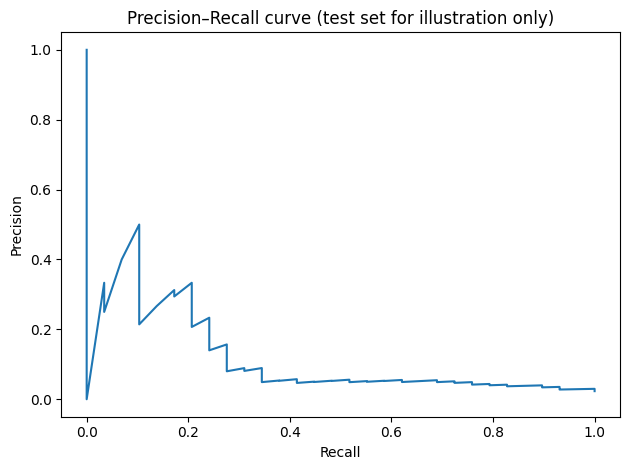

Positive prevalence baseline: 0.0232


In [6]:
precision, recall, thresholds = precision_recall_curve(y_test, test_prob)
plt.plot(recall, precision)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall curve (test set for illustration only)")
plt.tight_layout()
plt.show()
print("Positive prevalence baseline:", round(y_test.mean(), 4))

> **Method note:** the preceding curve is displayed to teach interpretation only. Do not use it to choose a threshold for the reported test results. For threshold selection, split a validation subset from the training data and choose the threshold there.

In [7]:
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train, test_size=0.25, stratify=y_train, random_state=7
)
threshold_model = Pipeline([
    ("scale", StandardScaler()),
    ("model", LogisticRegression(class_weight="balanced", max_iter=2000,
                                 random_state=RANDOM_STATE))
])
threshold_model.fit(X_fit, y_fit)
val_prob = threshold_model.predict_proba(X_val)[:, 1]
val_precision, val_recall, val_thresholds = precision_recall_curve(y_val, val_prob)

target_recall = 0.80
eligible = np.flatnonzero(val_recall[:-1] >= target_recall)
if len(eligible):
    idx = eligible[np.argmax(val_precision[:-1][eligible])]
    chosen_threshold = val_thresholds[idx]
    print("Chosen validation threshold:", round(float(chosen_threshold), 4))
    print("Validation precision:", round(float(val_precision[idx]), 4))
    print("Validation recall:", round(float(val_recall[idx]), 4))
else:
    chosen_threshold = 0.5
    print("Target recall not achieved; using 0.5 for this demonstration.")

Chosen validation threshold: 0.268
Validation precision: 0.0409
Validation recall: 0.8636


## 6. Final evaluation at a preselected threshold
The threshold was selected from validation data above. Apply it to the untouched test predictions.

Threshold: 0.268
Precision: 0.0379
Recall: 0.8966
F1: 0.0727
Average precision: 0.1245


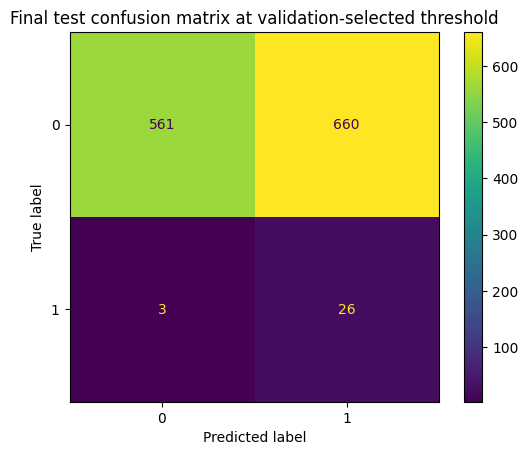

In [8]:
threshold_model.fit(X_train, y_train)
final_prob = threshold_model.predict_proba(X_test)[:, 1]
final_pred = (final_prob >= chosen_threshold).astype(int)
print("Threshold:", round(float(chosen_threshold), 4))
print("Precision:", round(precision_score(y_test, final_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, final_pred, zero_division=0), 4))
print("F1:", round(f1_score(y_test, final_pred, zero_division=0), 4))
print("Average precision:", round(average_precision_score(y_test, final_prob), 4))
ConfusionMatrixDisplay.from_predictions(y_test, final_pred)
plt.title("Final test confusion matrix at validation-selected threshold")
plt.show()

## 7. Tune SMOTE and model regularization with cross-validation
This search uses only the training partition. All scaling and sampling remain inside the pipeline.

In [9]:
smote_pipeline = Pipeline([
    ("scale", StandardScaler()),
    ("sampler", SMOTE(random_state=RANDOM_STATE)),
    ("model", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
])
param_grid = {
    "sampler__k_neighbors": [3, 5],
    "model__C": [0.1, 1.0, 10.0],
}
search = GridSearchCV(
    smote_pipeline, param_grid, scoring="average_precision", cv=cv, n_jobs=-1
)
search.fit(X_train, y_train)
print("Best parameters:", search.best_params_)
print("Best mean CV average precision:", round(search.best_score_, 4))

Best parameters: {'model__C': 1.0, 'sampler__k_neighbors': 5}
Best mean CV average precision: 0.1527


## 8. Reflection
1. How did class weighting change precision and recall?
2. Did any sampler improve average precision over the unmodified baseline?
3. How does average precision compare with positive-class prevalence?
4. What threshold fits the operational cost of false positives and false negatives?
5. What monitoring is needed when prevalence or data quality changes?

**Takeaway:** handle imbalance through careful metrics, leakage-safe validation, and cost-aware decisions—not by blindly balancing every dataset.